#Notebook 1 — Statistical Analysis
* Mann–Whitney tests
* FDR correction
* Volcano plot
* Significant taxa table

## Mann-Whitney

**Why Mann–Whitney?**

Microbiome abundances

aren't normally distributed
contain many zeros
are skewed

So we avoid a t-test.

Instead we use the Mann–Whitney U test.

In [1]:
import pandas as pd
import numpy as np

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load metadata
metadata = pd.read_csv("metadata.tsv", sep="\t")
species = pd.read_csv("species.tsv.zip", sep="\t", index_col=0)

In [4]:
print("Metadata shape:", metadata.shape)
print("Species shape:", species.shape)

metadata.head()

Metadata shape: (347, 15)
Species shape: (347, 57702)


,Dataset,Sample,Subject,Study.Group,Age,Age.Units,Gender,BMI,DOI,Publication.Name,Stage,Brinkman Index,Alcohol,Tumor location,Shared.w.ERAWIJANTARI_2020
0,YACHIDA_CRC_2019,10021,10021,Stage_I_II,57,Years,Male,26.880952,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,I,130,993.0,Left colon,False
1,YACHIDA_CRC_2019,10023,10023,Healthy,65,Years,Male,26.562500,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,660,0.0,-,False
2,YACHIDA_CRC_2019,10025,10025,Healthy,40,Years,Male,25.000000,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,400,993.0,-,True
3,YACHIDA_CRC_2019,10029,10029,Healthy,67,Years,Female,20.173253,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.0,-,False
4,YACHIDA_CRC_2019,10031,10031,Healthy,77,Years,Male,24.464602,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,300,813.0,-,False


In [5]:
species.head()

,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965,d__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795,d__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibacteraceae;g__JAAYPI01;s__JAAYPI01 sp012519885,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Flavobacteriaceae;g__Flavobacterium;s__Flavobacterium sp017989775,d__Bacteria;p__Gemmatimonadota;c__Gemmatimonadetes;o__Longimicrobiales;f__Longimicrobiaceae;g__Longimicrobium;s__Longimicrobium sp902805735,...,d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1;s__LC3-1 sp016781735,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Sphingomonadales;f__Sphingomonadaceae;g__Sphingorhabdus_B;s__Sphingorhabdus_B sp012032285,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Pseudomonadaceae;g__Pseudomonas_E;s__Pseudomonas_E sp900187445,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902591535,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales_A;f__Enterobacteriaceae_A;g__GCA-012562765;s__GCA-012562765 sp012569925,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902631135,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Puniceispirillales;f__Puniceispirillaceae;g__UBA5951;s__UBA5951 sp902625725,d__Bacteria;p__Verrucomicrobiota;c__Kiritimatiellae;o__SS1-B-03-39;f__UBA6053;g__PXAS01;s__PXAS01 sp003565815,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__HTCC2089;g__UBA7451;s__UBA7451 sp002457275,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__CACIJG01;s__CACIJG01 sp902580265
Sample,,,,,,,,,,,,,,,,,,,,,
10021,0.000181,0.0,0.0,0.000006,0.0,0.000002,1.301684e-06,3.154081e-06,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
10023,0.000499,0.0,0.0,0.000008,0.0,0.000002,2.213688e-06,0.000000e+00,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
10025,0.000018,0.0,0.0,0.000005,0.0,0.000002,2.976180e-07,0.000000e+00,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
10029,0.000051,0.0,0.0,0.000003,0.0,0.000005,4.691933e-07,2.580563e-07,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
10031,0.000011,0.0,0.0,0.000000,0.0,0.000002,5.167816e-07,0.000000e+00,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0


In [6]:
# Make sure sample IDs have the same type
metadata["Sample"] = metadata["Sample"].astype(str)
species.index = species.index.astype(str)

# Check overlap
common_samples = set(metadata["Sample"]).intersection(set(species.index))

print("Metadata samples:", metadata.shape[0])
print("Species samples:", species.shape[0])
print("Common samples:", len(common_samples))

Metadata samples: 347
Species samples: 347
Common samples: 347


In [7]:
# Match and reorder metadata to species table
metadata_matched = metadata[metadata["Sample"].isin(common_samples)].copy()
species_matched = species.loc[list(common_samples)].copy()

metadata_matched = metadata_matched.set_index("Sample")
metadata_matched = metadata_matched.loc[species_matched.index]

print("Matched metadata:", metadata_matched.shape)
print("Matched species:", species_matched.shape)

metadata_matched["Study.Group"].value_counts()

Matched metadata: (347, 14)
Matched species: (347, 57702)


,count
Study.Group,
Healthy,127
Stage_I_II,69
Stage_III_IV,54
MP,40
HS,30
Stage_0,27


Healthy vs Neoplasia = MP + Stage_0 + Stage_I_II + Stage_III_IV

In [8]:
# Remove HS group for the main Healthy vs Neoplasia comparison
keep_groups = ["Healthy", "MP", "Stage_0", "Stage_I_II", "Stage_III_IV"]

metadata_binary = metadata_matched[metadata_matched["Study.Group"].isin(keep_groups)].copy()
species_binary = species_matched.loc[metadata_binary.index].copy()

# Create binary label
metadata_binary["Binary.Group"] = np.where(
    metadata_binary["Study.Group"] == "Healthy",
    "Healthy",
    "Neoplasia"
)

print(metadata_binary["Study.Group"].value_counts())
print()
print(metadata_binary["Binary.Group"].value_counts())

print("Metadata binary:", metadata_binary.shape)
print("Species binary:", species_binary.shape)

Study.Group
Healthy         127
Stage_I_II       69
Stage_III_IV     54
MP               40
Stage_0          27
Name: count, dtype: int64

Binary.Group
Neoplasia    190
Healthy      127
Name: count, dtype: int64
Metadata binary: (317, 15)
Species binary: (317, 57702)


In [9]:
##Running Mann-Whitney for each species
results = []

for feature in species_binary.columns:

    # Split abundances by group
    healthy = species_binary.loc[
        metadata_binary["Binary.Group"] == "Healthy",
        feature
    ]

    neoplasia = species_binary.loc[
        metadata_binary["Binary.Group"] == "Neoplasia",
        feature
    ]

    # Mann–Whitney U test
    u_stat, p_value = mannwhitneyu(
        healthy,
        neoplasia,
        alternative="two-sided"
    )

    # Save results
    results.append({
        "Species": feature,
        "U_statistic": u_stat,
        "p_value": p_value
    })

# Convert to DataFrame
mw_results = pd.DataFrame(results)

# Display first few rows
mw_results.head()

,Species,U_statistic,p_value
0,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,10622.0,0.071246
1,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,11784.0,0.368913
2,d__Bacteria;p__Desulfobacterota_G;c__Syntropho...,12288.0,0.150103
3,d__Bacteria;p__Actinobacteriota;c__Actinomycet...,11792.0,0.733071
4,d__Bacteria;p__Firmicutes;c__Bacilli;o__Achole...,11904.5,0.719702


Mann–Whitney U tests were performed for 57,702 microbial species to compare abundance distributions between healthy controls and colorectal neoplasia samples. The resulting raw p-values were not interpreted directly because multiple testing correction was required.

## FDR correction

In [10]:
# Apply Benjamini-Hochberg FDR correction
mw_results["FDR"] = multipletests(
    mw_results["p_value"],
    method="fdr_bh"
)[1]

# Sort species by adjusted p-value
mw_results = mw_results.sort_values("FDR").reset_index(drop=True)

mw_results.head(10)

,Species,U_statistic,p_value,FDR
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,8337.0,0.000003,0.125059
1,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia...,8537.0,0.000006,0.125059
2,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,8467.0,0.000007,0.125059
3,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8632.0,0.000017,0.141112
4,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,15526.0,0.000015,0.141112
5,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,15392.5,0.000017,0.141112
6,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8648.0,0.000016,0.141112
7,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,8682.0,0.000023,0.168419
8,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8720.0,0.000029,0.171384
9,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,13859.0,0.000030,0.171384


In [11]:
print("Species with raw p < 0.05:", (mw_results["p_value"] < 0.05).sum())
print("Species with FDR < 0.05:", (mw_results["FDR"] < 0.05).sum())

Species with raw p < 0.05: 3138
Species with FDR < 0.05: 0


Before correction, 3,138 species appeared statistically significant.

However, after correcting for 57,702 simultaneous hypothesis tests, no species remained significant at an FDR threshold of 0.05.

This tells us that although many species show nominal differences between groups, the evidence is not strong enough to survive such a stringent multiple-testing correction.

A total of 57,702 Mann–Whitney U tests were performed to compare microbial species abundances between healthy individuals and patients with colorectal neoplasia. While 3,138 species showed nominal significance (raw p < 0.05), none remained significant after Benjamini–Hochberg FDR correction (FDR < 0.05). This likely reflects the large number of simultaneous statistical tests and the sparse nature of microbiome abundance data.

In [12]:
genera = pd.read_csv("genera.tsv", sep="\t", index_col=0)

print(genera.shape)
genera.head()

(347, 11942)


,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Monoglobales;f__Firm-18;g__UBA1775,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Peptostreptococcales;f__Acidaminobacteraceae;g__Fusibacter_A,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__Oceaniglobus,d__Bacteria;p__Myxococcota;c__Polyangia;o__Polyangiales;f__SG8-38;g__JAAYBZ01,d__Bacteria;p__Patescibacteria;c__Paceibacteria;o__UBA6257;f__02-FULL-45-10c;g__JACROC01,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__CAG-272;g__Flemingibacterium,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__F0428,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnoanaerobaculum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Carnobacteriaceae;g__Carnobacterium_A,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__GCA-900066755,...,d__Bacteria;p__Patescibacteria;c__Kazan-3B-28;o__Kazan-3B-28;f__UBA10110;g__JAHITC01,d__Bacteria;p__Patescibacteria;c__ABY1;o__SG8-24;f__2-12-FULL-60-25;g__RHKK01,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rickettsiales;f__UBA3002;g__UBA6178,d__Bacteria;p__Firmicutes;c__Bacilli;o__Mycoplasmatales;f__MT37;g__Spiroplasma_C,d__Bacteria;p__Desulfobacterota_E;c__MBNT15;o__J040;f__J040;g__WVXK01,d__Bacteria;p__Patescibacteria;c__Paceibacteria;o__2-02-FULL-40-12;f__IGHO2-01-FULL-4-A;g__VMGJ01,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__JABSSB01,d__Bacteria;p__Patescibacteria;c__Microgenomatia;o__Curtissbacterales;f__GWA2-41-24;g__JACQIV01,d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__HTCC2089;g__UBA7451
Sample,,,,,,,,,,,,,,,,,,,,,
10021,0.0,0.000001,0.000000e+00,0.0,0.0,9.042102e-07,0.000009,0.000022,3.807201e-07,0.000034,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
10023,0.0,0.000004,0.000000e+00,0.0,0.0,5.477831e-06,0.000022,0.000038,2.992093e-07,0.000019,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
10025,0.0,0.000001,9.466900e-07,0.0,0.0,2.734882e-06,0.000020,0.000042,9.466900e-07,0.000031,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
10029,0.0,0.000002,4.543136e-07,0.0,0.0,3.770803e-06,0.000014,0.000057,1.817254e-06,0.000290,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0
10031,0.0,0.000000,0.000000e+00,0.0,0.0,2.690259e-06,0.000010,0.000059,1.228162e-06,0.000027,...,0.0,0,0,0.0,0.0,0.0,0.0,0,0,0.0


## RE-doing using genera dataset

In [13]:
# Make sample IDs comparable
genera.index = genera.index.astype(str)
metadata["Sample"] = metadata["Sample"].astype(str)

# Match samples
common_samples = set(metadata["Sample"]).intersection(set(genera.index))

metadata_genera = metadata[metadata["Sample"].isin(common_samples)].copy()
genera_matched = genera.loc[list(common_samples)].copy()

metadata_genera = metadata_genera.set_index("Sample")
metadata_genera = metadata_genera.loc[genera_matched.index]

print("Matched metadata:", metadata_genera.shape)
print("Matched genera:", genera_matched.shape)

metadata_genera["Study.Group"].value_counts()

Matched metadata: (347, 14)
Matched genera: (347, 11942)


,count
Study.Group,
Healthy,127
Stage_I_II,69
Stage_III_IV,54
MP,40
HS,30
Stage_0,27


In [14]:
keep_groups = ["Healthy", "MP", "Stage_0", "Stage_I_II", "Stage_III_IV"]

metadata_genera_binary = metadata_genera[
    metadata_genera["Study.Group"].isin(keep_groups)
].copy()

genera_binary = genera_matched.loc[metadata_genera_binary.index].copy()

metadata_genera_binary["Binary.Group"] = np.where(
    metadata_genera_binary["Study.Group"] == "Healthy",
    "Healthy",
    "Neoplasia"
)

print(metadata_genera_binary["Binary.Group"].value_counts())
print("Genera before filtering:", genera_binary.shape)

Binary.Group
Neoplasia    190
Healthy      127
Name: count, dtype: int64
Genera before filtering: (317, 11942)


In [16]:
# Prevalence = proportion of samples where abundance > 0
prevalence = (genera_binary > 0).mean(axis=0)

# Keep genera present in at least 10% of samples
genera_filtered = genera_binary.loc[:, prevalence >= 0.10]

print("Genera before filtering:", genera_binary.shape[1])
print("Genera after filtering:", genera_filtered.shape[1])

Genera before filtering: 11942
Genera after filtering: 5265


In [17]:
metadata_genera_binary["Binary.Group"].value_counts()
genera_filtered.shape

(317, 5265)

We calculated the prevalence of each genus (the proportion of samples in which it had a non-zero abundance) and retained only genera present in at least 10% of samples.

Rare genera that appear in only a few samples contribute little statistical information but greatly increase the number of hypothesis tests. Removing them:

reduces the multiple testing burden,
improves statistical power,
makes downstream analyses more robust and interpretable.

In [18]:
results = []

for genus in genera_filtered.columns:

    healthy = genera_filtered.loc[
        metadata_genera_binary["Binary.Group"] == "Healthy",
        genus
    ]

    neoplasia = genera_filtered.loc[
        metadata_genera_binary["Binary.Group"] == "Neoplasia",
        genus
    ]

    u_stat, p_value = mannwhitneyu(
        healthy,
        neoplasia,
        alternative="two-sided"
    )

    results.append({
        "Genus": genus,
        "U_statistic": u_stat,
        "p_value": p_value
    })

mw_results = pd.DataFrame(results)

mw_results.head()

,Genus,U_statistic,p_value
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,12968.0,0.256594
1,d__Bacteria;p__Proteobacteria;c__Alphaproteoba...,11638.0,0.505772
2,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__O...,12571.0,0.527275
3,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,11897.0,0.834085
4,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,10833.0,0.123550


The output contains raw p-values only, so we still cannot claim significant genera yet. Next we apply FDR correction again.

In [19]:
# Apply Benjamini-Hochberg FDR correction
mw_results["FDR"] = multipletests(
    mw_results["p_value"],
    method="fdr_bh"
)[1]

# Sort by FDR
mw_results = mw_results.sort_values("FDR").reset_index(drop=True)

mw_results.head(10)

,Genus,U_statistic,p_value,FDR
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,15561.0,0.000012,0.032518
1,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,8569.0,0.000012,0.032518
2,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8786.5,0.000037,0.048205
3,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,13857.0,0.000030,0.048205
4,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,14852.5,0.000089,0.081471
5,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia...,8939.0,0.000093,0.081471
6,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8974.0,0.000110,0.082810
7,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,9019.0,0.000140,0.092004
8,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,9045.0,0.000159,0.093225
9,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__P...,9084.0,0.000194,0.101924


In [20]:
print("Genera with raw p < 0.05:", (mw_results["p_value"] < 0.05).sum())
print("Genera with FDR < 0.05:", (mw_results["FDR"] < 0.05).sum())

Genera with raw p < 0.05: 398
Genera with FDR < 0.05: 4


Before correction, 398 genera appeared to differ significantly between Healthy and Neoplasia.

After controlling for multiple testing with the Benjamini–Hochberg procedure, 4 genera remained statistically significant (FDR < 0.05). These are the strongest candidate microbial biomarkers associated with colorectal neoplasia in this dataset.

This is a much more realistic and biologically meaningful result than when testing all 57,702 species.

Differential abundance analysis identified 398 genera with nominal significance (raw p < 0.05). After Benjamini–Hochberg correction for multiple testing, 4 genera remained significantly associated with colorectal neoplasia (FDR < 0.05). These genera represent the most robust microbial candidates for downstream biological interpretation and machine learning analyses.

In [21]:
# Keep only significant genera
significant_genera = mw_results[mw_results["FDR"] < 0.05]

print(significant_genera.shape)

significant_genera

(4, 4)


,Genus,U_statistic,p_value,FDR
0,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,15561.0,0.000012,0.032518
1,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,8569.0,0.000012,0.032518
2,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8786.5,0.000037,0.048205
3,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,13857.0,0.000030,0.048205


In [22]:
# Extract the genus name after "g__"
mw_results["Genus_clean"] = mw_results["Genus"].str.extract(r"g__([^;]+)$")

# Put clean name first
mw_results = mw_results[
    ["Genus_clean", "Genus", "U_statistic", "p_value", "FDR"]
]

significant_genera = mw_results[mw_results["FDR"] < 0.05]

significant_genera

,Genus_clean,Genus,U_statistic,p_value,FDR
0,Lachnospira,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,15561.0,0.000012,0.032518
1,Parvimonas,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,8569.0,0.000012,0.032518
2,RGIG1874,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8786.5,0.000037,0.048205
3,Lonepinella,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,13857.0,0.000030,0.048205


In [23]:
mean_healthy = genera_filtered.loc[
    metadata_genera_binary["Binary.Group"] == "Healthy"
].mean(axis=0)

mean_neoplasia = genera_filtered.loc[
    metadata_genera_binary["Binary.Group"] == "Neoplasia"
].mean(axis=0)

mw_results["mean_healthy"] = mw_results["Genus"].map(mean_healthy)
mw_results["mean_neoplasia"] = mw_results["Genus"].map(mean_neoplasia)

mw_results["log2FC_neoplasia_vs_healthy"] = np.log2(
    (mw_results["mean_neoplasia"] + 1e-9) /
    (mw_results["mean_healthy"] + 1e-9)
)

mw_results["Direction"] = np.where(
    mw_results["log2FC_neoplasia_vs_healthy"] > 0,
    "Enriched in Neoplasia",
    "Enriched in Healthy"
)

significant_genera = mw_results[mw_results["FDR"] < 0.05]

significant_genera[
    ["Genus_clean", "mean_healthy", "mean_neoplasia",
     "log2FC_neoplasia_vs_healthy", "p_value", "FDR", "Direction"]
]

,Genus_clean,mean_healthy,mean_neoplasia,log2FC_neoplasia_vs_healthy,p_value,FDR,Direction
0,Lachnospira,2.651921e-02,1.437770e-02,-0.883205,0.000012,0.032518,Enriched in Healthy
1,Parvimonas,4.183183e-05,1.909459e-04,2.190464,0.000012,0.032518,Enriched in Neoplasia
2,RGIG1874,6.335026e-06,1.348634e-05,1.089956,0.000037,0.048205,Enriched in Neoplasia
3,Lonepinella,1.330532e-07,3.353990e-08,-1.956470,0.000030,0.048205,Enriched in Healthy


Following prevalence filtering and multiple testing correction, four genera remained significantly associated with colorectal neoplasia. Parvimonas was enriched in neoplasia samples, consistent with previous reports linking this genus to colorectal cancer. In contrast, Lachnospira was more abundant in healthy individuals, supporting its proposed role as a beneficial gut commensal. The remaining significant genera (RGIG1874 and Lonepinella) showed significant abundance differences but require cautious interpretation due to their limited characterization or low abundance.

In [24]:
significant_genera.to_csv(
    "significant_genera_mannwhitney_FDR005.csv",
    index=False
)

# Volcano plot

raw pvalues

In [30]:
# Create plotting dataframe
volcano_raw = mw_results.copy()

# -log10(raw p-value)
volcano_raw["minus_log10_p"] = -np.log10(volcano_raw["p_value"])

# Raw significance
volcano_raw["Raw_Significant"] = volcano_raw["p_value"] < 0.05

# Clip x-axis for visualization only
volcano_raw["log2FC_plot"] = volcano_raw["log2FC_neoplasia_vs_healthy"].clip(-3, 3)

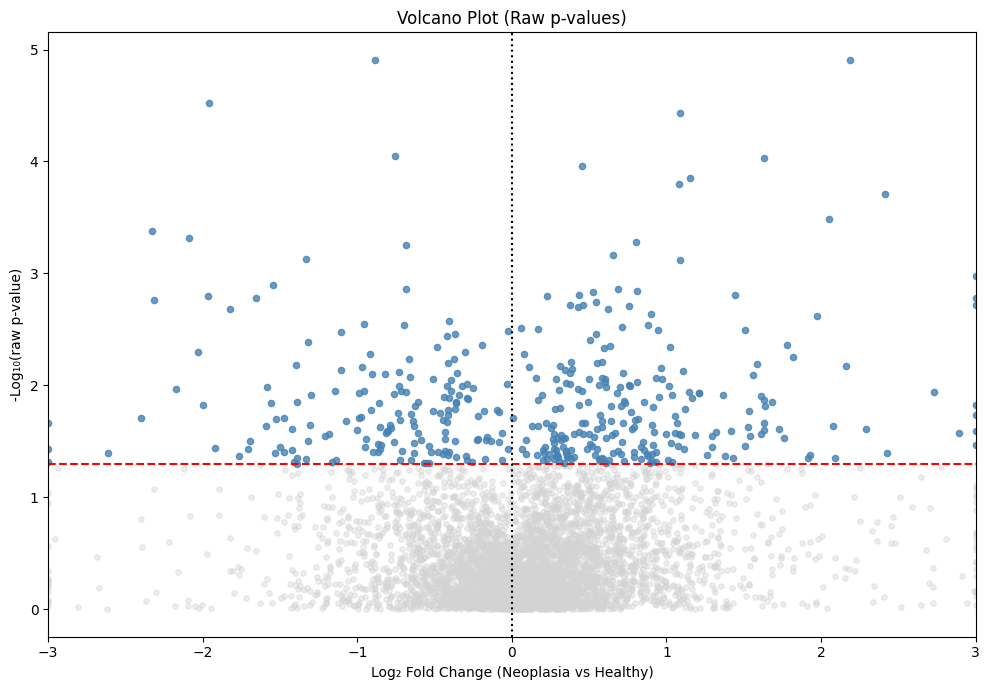

In [31]:
plt.figure(figsize=(10,7))

# Non-significant
plt.scatter(
    volcano_raw.loc[~volcano_raw["Raw_Significant"], "log2FC_plot"],
    volcano_raw.loc[~volcano_raw["Raw_Significant"], "minus_log10_p"],
    color="lightgray",
    alpha=0.4,
    s=15
)

# Significant
plt.scatter(
    volcano_raw.loc[volcano_raw["Raw_Significant"], "log2FC_plot"],
    volcano_raw.loc[volcano_raw["Raw_Significant"], "minus_log10_p"],
    color="steelblue",
    alpha=0.8,
    s=20
)

plt.axhline(-np.log10(0.05),
            linestyle="--",
            color="red")

plt.axvline(0,
            linestyle=":",
            color="black")

plt.xlabel("Log₂ Fold Change (Neoplasia vs Healthy)")
plt.ylabel("-Log₁₀(raw p-value)")
plt.title("Volcano Plot (Raw p-values)")

plt.xlim(-3,3)

plt.tight_layout()
plt.show()

The raw p-value volcano plot was generated as an exploratory visualization to illustrate the overall distribution of effect sizes and nominal statistical significance. Although 398 genera showed raw p < 0.05, only four remained significant after Benjamini–Hochberg FDR correction. Therefore, biological conclusions were based on the FDR-corrected results, while the raw p-value volcano plot was used only for visualization.

In [25]:
# Calculate -log10(FDR)
mw_results["minus_log10_FDR"] = -np.log10(mw_results["FDR"])

# Label significant genera
mw_results["Significant"] = mw_results["FDR"] < 0.05

mw_results.head()

,Genus_clean,Genus,U_statistic,p_value,FDR,mean_healthy,mean_neoplasia,log2FC_neoplasia_vs_healthy,Direction,minus_log10_FDR,Significant
0,Lachnospira,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__L...,15561.0,0.000012,0.032518,2.651921e-02,1.437770e-02,-0.883205,Enriched in Healthy,1.487875,True
1,Parvimonas,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__T...,8569.0,0.000012,0.032518,4.183183e-05,1.909459e-04,2.190464,Enriched in Neoplasia,1.487875,True
2,RGIG1874,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__...,8786.5,0.000037,0.048205,6.335026e-06,1.348634e-05,1.089956,Enriched in Neoplasia,1.316909,True
3,Lonepinella,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,13857.0,0.000030,0.048205,1.330532e-07,3.353990e-08,-1.956470,Enriched in Healthy,1.316909,True
4,Chitinibacter,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,14852.5,0.000089,0.081471,5.426245e-07,3.206893e-07,-0.756943,Enriched in Healthy,1.088999,False


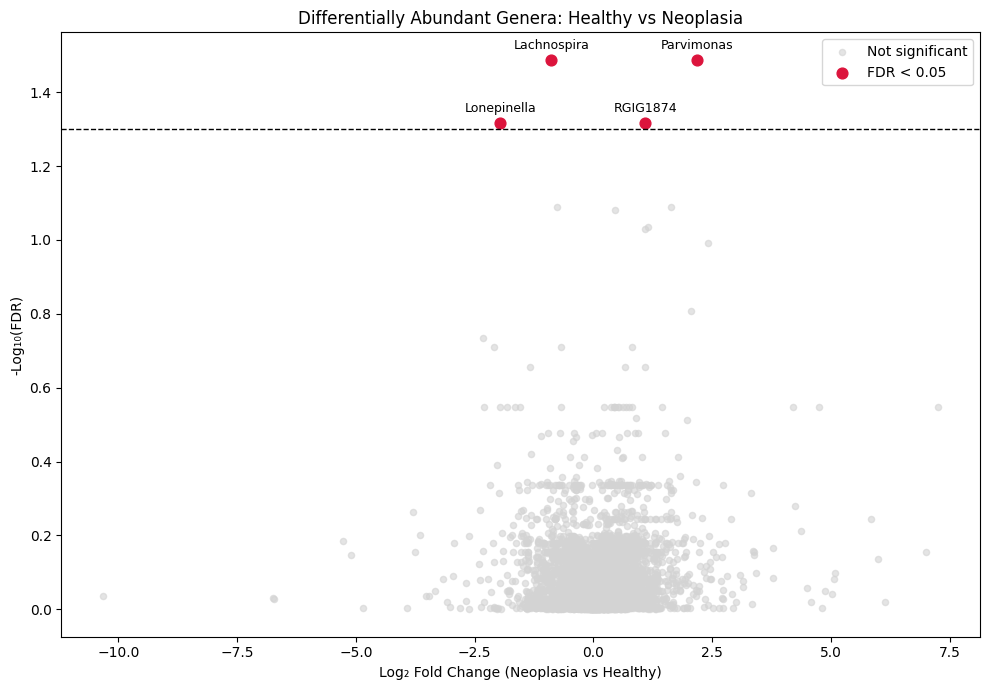

In [27]:
plt.figure(figsize=(10, 7))

plt.scatter(
    mw_results.loc[~mw_results["Significant"], "log2FC_neoplasia_vs_healthy"],
    mw_results.loc[~mw_results["Significant"], "minus_log10_FDR"],
    color="lightgray",
    alpha=0.6,
    s=20,
    label="Not significant"
)

plt.scatter(
    mw_results.loc[mw_results["Significant"], "log2FC_neoplasia_vs_healthy"],
    mw_results.loc[mw_results["Significant"], "minus_log10_FDR"],
    color="crimson",
    s=60,
    label="FDR < 0.05"
)

plt.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=1)

for _, row in mw_results[mw_results["Significant"]].iterrows():
    plt.text(
        row["log2FC_neoplasia_vs_healthy"],
        row["minus_log10_FDR"] + 0.03,
        row["Genus_clean"],
        fontsize=9,
        ha="center"
    )

plt.xlabel("Log₂ Fold Change (Neoplasia vs Healthy)")
plt.ylabel("-Log₁₀(FDR)")
plt.title("Differentially Abundant Genera: Healthy vs Neoplasia")
plt.legend()
plt.tight_layout()
plt.show()

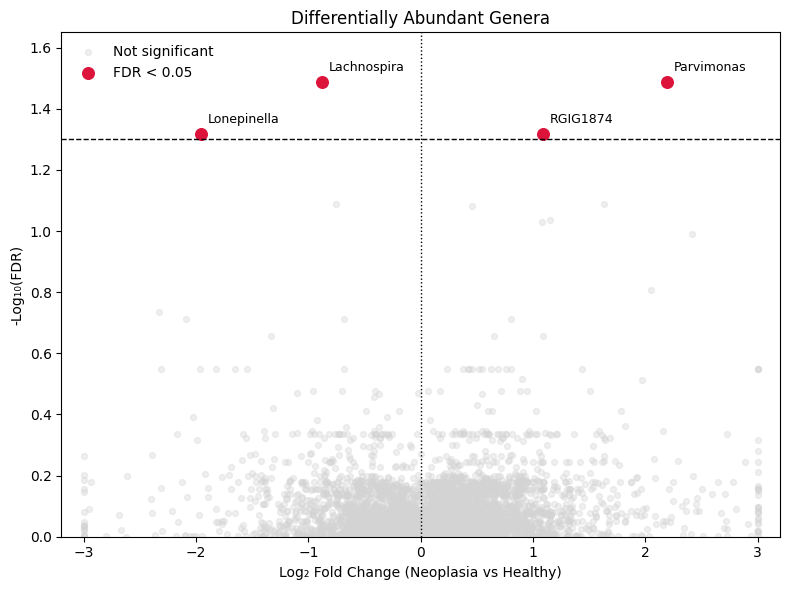

In [28]:
plot_df = mw_results.copy()

# Limit extreme fold-change values for visualization only
plot_df["log2FC_clipped"] = plot_df["log2FC_neoplasia_vs_healthy"].clip(-3, 3)

plt.figure(figsize=(8, 6))

plt.scatter(
    plot_df.loc[~plot_df["Significant"], "log2FC_clipped"],
    plot_df.loc[~plot_df["Significant"], "minus_log10_FDR"],
    color="lightgray",
    alpha=0.35,
    s=18,
    label="Not significant"
)

plt.scatter(
    plot_df.loc[plot_df["Significant"], "log2FC_clipped"],
    plot_df.loc[plot_df["Significant"], "minus_log10_FDR"],
    color="crimson",
    s=70,
    label="FDR < 0.05"
)

plt.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=1)
plt.axvline(0, color="black", linestyle=":", linewidth=1)

for _, row in plot_df[plot_df["Significant"]].iterrows():
    plt.annotate(
        row["Genus_clean"],
        xy=(row["log2FC_clipped"], row["minus_log10_FDR"]),
        xytext=(5, 8),
        textcoords="offset points",
        fontsize=9
    )

plt.xlim(-3.2, 3.2)
plt.ylim(0, 1.65)

plt.xlabel("Log₂ Fold Change (Neoplasia vs Healthy)")
plt.ylabel("-Log₁₀(FDR)")
plt.title("Differentially Abundant Genera")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Because only four genera passed FDR correction, a ranked bar plot is more informative than a volcano plot. Parvimonas and RGIG1874 showed higher abundance in neoplasia, while Lachnospira and Lonepinella were higher in healthy controls.

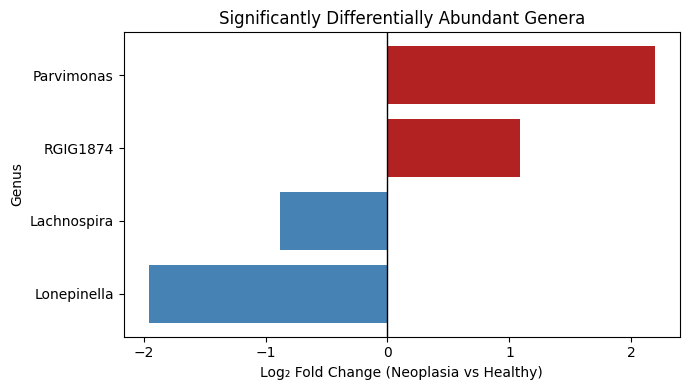

In [32]:
colors = [
    "steelblue" if x < 0 else "firebrick"
    for x in sig_plot["log2FC_neoplasia_vs_healthy"]
]

plt.figure(figsize=(7,4))

plt.barh(
    sig_plot["Genus_clean"],
    sig_plot["log2FC_neoplasia_vs_healthy"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Log₂ Fold Change (Neoplasia vs Healthy)")
plt.ylabel("Genus")
plt.title("Significantly Differentially Abundant Genera")

plt.tight_layout()
plt.show()

The vertical line at 0 clearly separates:
Left: enriched in Healthy
Right: enriched in Neoplasia
The length of the bars shows the magnitude of the log₂ fold change.
There is no visual clutter from the 5,261 non-significant genera.

Following prevalence filtering and FDR correction, four genera remained significantly associated with colorectal neoplasia. Parvimonas and RGIG1874 showed higher abundance in neoplasia samples, whereas Lachnospira and Lonepinella were enriched in healthy controls. Among these, Parvimonas exhibited the largest positive log₂ fold change, indicating the strongest enrichment in neoplasia, while Lonepinella showed the greatest enrichment in healthy individuals.

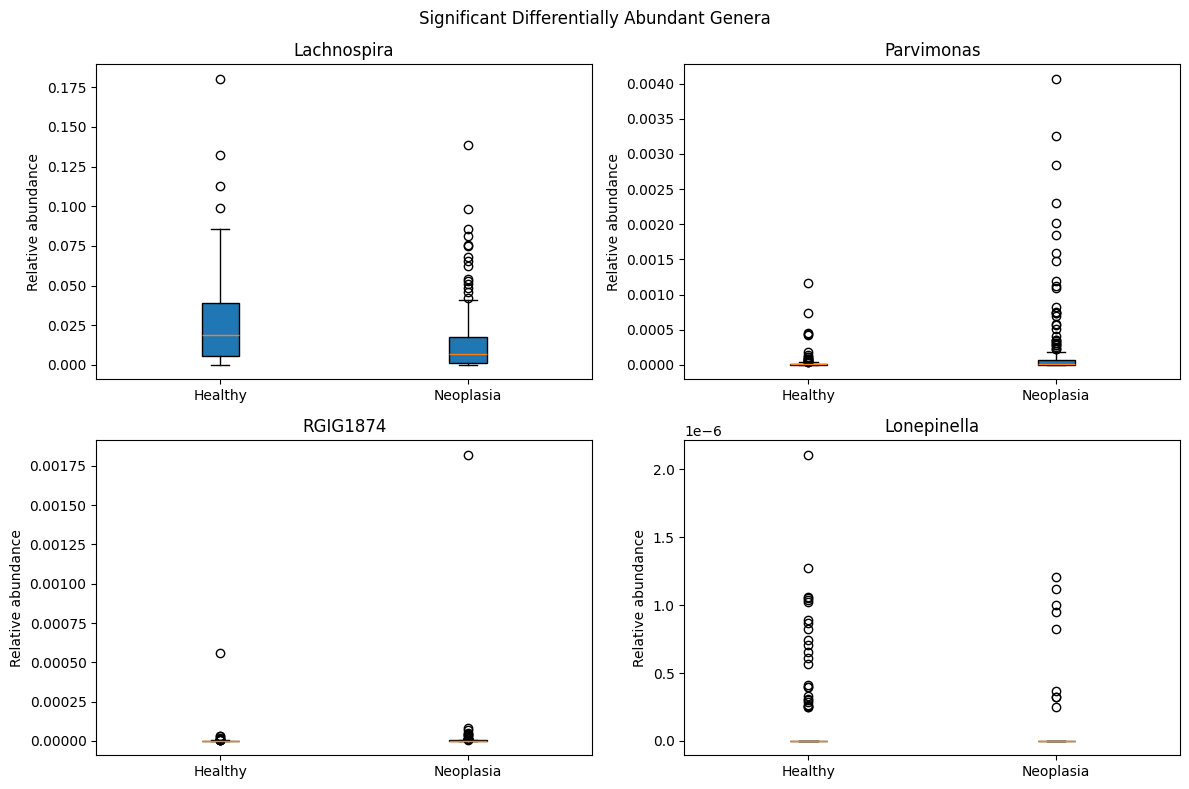

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes = axes.flatten()

for ax, genus in zip(axes, significant_genera["Genus"]):

    plot_df = pd.DataFrame({
        "Abundance": genera_filtered[genus],
        "Group": metadata_genera_binary["Binary.Group"],
    })

    ax.boxplot(
        [
            plot_df.loc[plot_df["Group"] == "Healthy", "Abundance"],
            plot_df.loc[plot_df["Group"] == "Neoplasia", "Abundance"],
        ],
        tick_labels=["Healthy", "Neoplasia"],
        patch_artist=True
    )

    ax.set_title(
        significant_genera.loc[
            significant_genera["Genus"] == genus,
            "Genus_clean"
        ].values[0]
    )

    ax.set_ylabel("Relative abundance")

plt.suptitle("Significant Differentially Abundant Genera")

plt.tight_layout()

plt.show()

Each panel compares the relative abundance of one significant genus between:

Healthy (left)
Neoplasia (right)

The orange line is the median abundance, the box is the interquartile range (middle 50% of samples), the whiskers show the spread of most observations, and the circles are outliers.

Remember that the Mann–Whitney U test compares the overall distributions of the two groups, not just their medians.

Lachnospira is a well-known short-chain fatty acid (SCFA)-producing genus. SCFAs, especially butyrate, contribute to gut barrier integrity and have anti-inflammatory properties. A reduction in Lachnospira has been reported in several colorectal cancer studies, making this finding biologically plausible.


What do we see?
Healthy individuals have a higher median abundance.
The Healthy group also has a wider distribution.
Neoplasia samples have generally lower abundances.

This agrees with your earlier result:

log₂FC = −0.88
Direction = Enriched in Healthy

**Parvimonas**
What do we see?

Most samples have abundances close to zero, but:

Healthy individuals have very few high-abundance samples.
Neoplasia contains many more high-abundance outliers.
The median is also shifted upward in Neoplasia.

This matches:

log₂FC = +2.19
Direction = Enriched in Neoplasia
Biological interpretation

This is probably your most interesting finding.

Parvimonas has been repeatedly associated with colorectal cancer in previous studies. Your data show that while it is absent or rare in many individuals, a subset of neoplasia patients have substantially higher abundances, which is enough to produce a significant difference.

**RGIG1874**

What do we see?

Almost every sample has extremely low abundance.

Only a handful of Neoplasia samples show noticeably higher values.

This explains why:

it is statistically significant,
but the boxplot looks almost empty.
Interpretation

This genus appears to be rare, but when present it tends to occur at higher abundance in neoplasia.

Since it is poorly characterized, you should avoid making strong biological claims and simply report it as a significant genus requiring further investigation.

**Lonepinella**

What do we see?

Again, abundance is extremely low.

Healthy individuals show more high-abundance observations than Neoplasia.

This matches your negative log₂FC.

Interpretation

Although statistically significant, the absolute abundances are very small. Therefore, its biological importance should be interpreted cautiously despite the statistical result.

Why do many plots look "flat"?

This is normal for microbiome data.

Most genera:

have abundance = 0 in many samples,
are highly right-skewed,
contain a few very high-abundance observations.

That is exactly why you used the Mann–Whitney U test, which does not assume a normal distribution.

Boxplots of the four FDR-significant genera demonstrated distinct abundance distributions between healthy individuals and patients with colorectal neoplasia. Lachnospira exhibited higher abundances in healthy controls, whereas Parvimonas showed markedly increased abundance in neoplasia samples. RGIG1874 and Lonepinella also differed significantly between groups, although both were present at very low abundances, indicating that their biological relevance should be interpreted cautiously. Overall, the boxplots support the results of the Mann–Whitney U tests by illustrating both the direction and variability of abundance differences between groups.

One thing you'll notice is that Parvimonas, RGIG1874, and Lonepinella have many zeros and a few larger values. This is typical of microbiome datasets, but it also means that the statistical significance is driven by differences in the distributions, not necessarily by large shifts in the median abundance. That's exactly what the Mann–Whitney U test is designed to detect, and it's worth mentioning because it shows you understand the strengths and limitations of the method.

Differential abundance testing was initially explored at the species level; however, no species remained significant after FDR correction due to the large number of hypothesis tests (57,702 species). Therefore, the primary analysis was performed at the genus level after prevalence filtering, which reduced the feature space to 5,265 genera and identified four genera that remained significant after FDR correction.

# **Notebook 2 — Correlation Analysis**
* Spearman correlations
* Heatmaps
* Network (optional)

In [42]:
#import pandas as pd
#import numpy as np

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
#import matplotlib.pyplot as plt
#import seaborn as sns

In [35]:
metadata = pd.read_csv("metadata.tsv", sep="\t")

genera = pd.read_csv("genera.tsv", sep="\t", index_col=0)

mtb = pd.read_csv("mtb.tsv", sep="\t", index_col=0)

print("Metadata:", metadata.shape)
print("Genera:", genera.shape)
print("Metabolomics:", mtb.shape)

Metadata: (347, 15)
Genera: (347, 11942)
Metabolomics: (347, 450)


In [37]:
# Ensure sample IDs are strings
metadata["Sample"] = metadata["Sample"].astype(str)
genera.index = genera.index.astype(str)
mtb.index = mtb.index.astype(str)

# Find common samples
common_samples = (
    set(metadata["Sample"])
    .intersection(genera.index)
    .intersection(mtb.index)
)

print("Common samples:", len(common_samples))

# Keep only common samples
metadata_corr = metadata[metadata["Sample"].isin(common_samples)].copy()
metadata_corr = metadata_corr.set_index("Sample")

genera_corr = genera.loc[list(common_samples)].copy()
mtb_corr = mtb.loc[list(common_samples)].copy()

# Reorder to match metadata
metadata_corr = metadata_corr.loc[genera_corr.index]
mtb_corr = mtb_corr.loc[genera_corr.index]

print("Metadata:", metadata_corr.shape)
print("Genera:", genera_corr.shape)
print("Metabolomics:", mtb_corr.shape)

Common samples: 347
Metadata: (347, 14)
Genera: (347, 11942)
Metabolomics: (347, 450)


This step ensures that the microbiome, metabolomics, and metadata tables contain the same participants in the same order. Proper sample alignment is essential in multi-omics analyses because correlations must be calculated between measurements from the same individual. Misaligned samples would produce incorrect associations.

Before combining multiple omics datasets, we should ensure they all use the same sample identifiers as the index, so that measurements from the same individual are correctly aligned across datasets. Failing to do this can lead to comparing data from different participants, which would invalidate downstream analyses.

 the change from 15 → 14 columns is expected and correct.

In [38]:
# Keep only significant genera
selected_genera = significant_genera["Genus"].tolist()

genera_sig = genera_corr[selected_genera]

print(genera_sig.shape)
genera_sig.head()

(347, 4)


,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Lachnospira,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Tissierellales;f__Peptoniphilaceae;g__Parvimonas,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae;g__RGIG1874,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Pasteurellaceae;g__Lonepinella
Sample,,,,
10048,0.052222,0.000007,0.000000e+00,2.487103e-07
10206,0.009029,0.000002,2.785336e-07,0.000000e+00
10759,0.040945,0.000007,3.734566e-05,0.000000e+00
10525,0.000767,0.000147,0.000000e+00,0.000000e+00
10283,0.013901,0.000003,3.574662e-07,0.000000e+00


The microbiome dataset has been reduced to the four genera that showed significant differential abundance between Healthy and Neoplasia in Notebook 1. Focusing on these genera reduces the number of statistical tests and allows us to investigate whether the strongest microbial biomarkers are associated with metabolite abundances.

In [39]:
# Rename columns to clean genus names
clean_names = significant_genera.set_index("Genus")["Genus_clean"].to_dict()

genera_sig_clean = genera_sig.rename(columns=clean_names)

genera_sig_clean.head()

,Lachnospira,Parvimonas,RGIG1874,Lonepinella
Sample,,,,
10048,0.052222,0.000007,0.000000e+00,2.487103e-07
10206,0.009029,0.000002,2.785336e-07,0.000000e+00
10759,0.040945,0.000007,3.734566e-05,0.000000e+00
10525,0.000767,0.000147,0.000000e+00,0.000000e+00
10283,0.013901,0.000003,3.574662e-07,0.000000e+00


In [43]:
corr_results = []

for genus in genera_sig_clean.columns:
    for metabolite in mtb_corr.columns:

        rho, p_value = spearmanr(
            genera_sig_clean[genus],
            mtb_corr[metabolite]
        )

        corr_results.append({
            "Genus": genus,
            "Metabolite": metabolite,
            "Spearman_rho": rho,
            "p_value": p_value
        })

corr_results = pd.DataFrame(corr_results)

print(corr_results.shape)
corr_results.head()

/tmp/ipykernel_9278/414526875.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p_value = spearmanr(


(1800, 4)


,Genus,Metabolite,Spearman_rho,p_value
0,Lachnospira,C00024_Acetyl CoA,0.117365,0.028820
1,Lachnospira,C01996_Acetylcholine,-0.102038,0.057584
2,Lachnospira,C00147_Adenine,0.062430,0.246102
3,Lachnospira,C00212_Adenosine,-0.005725,0.915381
4,Lachnospira,"C00054_Adenosine 3',5'-diphosphate",0.097375,0.070039


ConstantInputWarning means that for some metabolite columns, all values are the same across samples, for example all zeros.

Spearman correlation cannot be calculated if one variable is constant because there is no variation to rank.

So for those pairs, rho and/or p_value may become NaN.

That is normal in omics data.

Spearman correlation tests whether each genus has a monotonic association with each metabolite across the same 347 individuals. Positive rho means higher genus abundance tends to occur with higher metabolite abundance; negative rho means higher genus abundance tends to occur with lower metabolite abundance.

we calculated 1,800 Spearman correlations:

4 genera × 450 metabolites = 1,800 tests

Each test asks whether a genus abundance is monotonically associated with a metabolite abundance across the same 347 paired samples.

Example:

Lachnospira vs Acetyl CoA
rho = 0.117
p = 0.0288

This is a weak positive raw association, but we cannot interpret it yet because FDR correction has not been applied.

In [44]:
# Remove correlations where Spearman could not be calculated
corr_results_clean = corr_results.dropna(subset=["Spearman_rho", "p_value"]).copy()

print("Before removing NaNs:", corr_results.shape)
print("After removing NaNs:", corr_results_clean.shape)

Before removing NaNs: (1800, 4)
After removing NaNs: (1784, 4)


In [45]:
# FDR correction
corr_results_clean["FDR"] = multipletests(
    corr_results_clean["p_value"],
    method="fdr_bh"
)[1]

# Sort by FDR
corr_results_clean = corr_results_clean.sort_values("FDR").reset_index(drop=True)

corr_results_clean.head(10)

,Genus,Metabolite,Spearman_rho,p_value,FDR
0,Parvimonas,C00079_Phe,0.485389,6.534112e-22,1.165686e-18
1,Parvimonas,C00183_Val,0.469761,1.896465e-20,1.691647e-17
2,Parvimonas,C00123_Leu,0.464523,5.644676e-20,3.356701e-17
3,Parvimonas,C02571_o-Acetylcarnitine,0.451168,8.379838e-19,3.737408e-16
4,Parvimonas,C00491_Cystine,0.446637,2.037529e-18,7.269905e-16
5,Parvimonas,C00719_Betaine,0.440763,6.323868e-18,1.880297e-15
6,Parvimonas,C00300_Creatine,0.435202,1.810979e-17,4.615410e-15
7,Parvimonas,C00114_Choline,0.421093,2.399298e-16,5.350435e-14
8,Parvimonas,C00037_Gly,0.420316,2.756544e-16,5.464084e-14
9,Parvimonas,C00407_Ile,0.411780,1.237493e-15,2.207687e-13


In [46]:
print("Raw p < 0.05:", (corr_results_clean["p_value"] < 0.05).sum())
print("FDR < 0.05:", (corr_results_clean["FDR"] < 0.05).sum())

Raw p < 0.05: 475
FDR < 0.05: 290


Initial correlations: 1,800
Removed undefined correlations: 16
Final correlations tested: 1,784

The removed correlations involved metabolites with constant values across all samples, for which Spearman correlation cannot be computed. Excluding these variables ensures valid statistical testing.

**Multiple testing**
| Stage        | Number  |
| ------------ | ------- |
| Raw p < 0.05 | **475** |
| FDR < 0.05   | **290** |

Unlike Notebook 1, many associations remained significant after FDR correction.

This suggests that the significant microbial genera identified in Notebook 1 are strongly associated with metabolite profiles, supporting the existence of coordinated microbiome–metabolome alterations in colorectal neoplasia.

**The strongest correlations are all with Parvimonas.**

| Metabolite      | ρ         |
| --------------- | --------- |
| Phenylalanine   | **0.485** |
| Valine          | **0.470** |
| Leucine         | **0.465** |
| Acetylcarnitine | **0.451** |
| Cystine         | **0.447** |


These are moderate positive correlations.

That means:

Individuals with higher Parvimonas abundance also tend to have higher concentrations of these metabolites.

This does not imply causation, but it suggests that Parvimonas may be associated with altered amino acid and energy metabolism in colorectal neoplasia.

In [47]:
significant_corr = corr_results_clean[
    corr_results_clean["FDR"] < 0.05
].copy()

print(significant_corr.shape)

significant_corr.head()

(290, 5)


,Genus,Metabolite,Spearman_rho,p_value,FDR
0,Parvimonas,C00079_Phe,0.485389,6.534112e-22,1.165686e-18
1,Parvimonas,C00183_Val,0.469761,1.896465e-20,1.691647e-17
2,Parvimonas,C00123_Leu,0.464523,5.644676e-20,3.356701e-17
3,Parvimonas,C02571_o-Acetylcarnitine,0.451168,8.379838e-19,3.737408e-16
4,Parvimonas,C00491_Cystine,0.446637,2.037529e-18,7.269905e-16


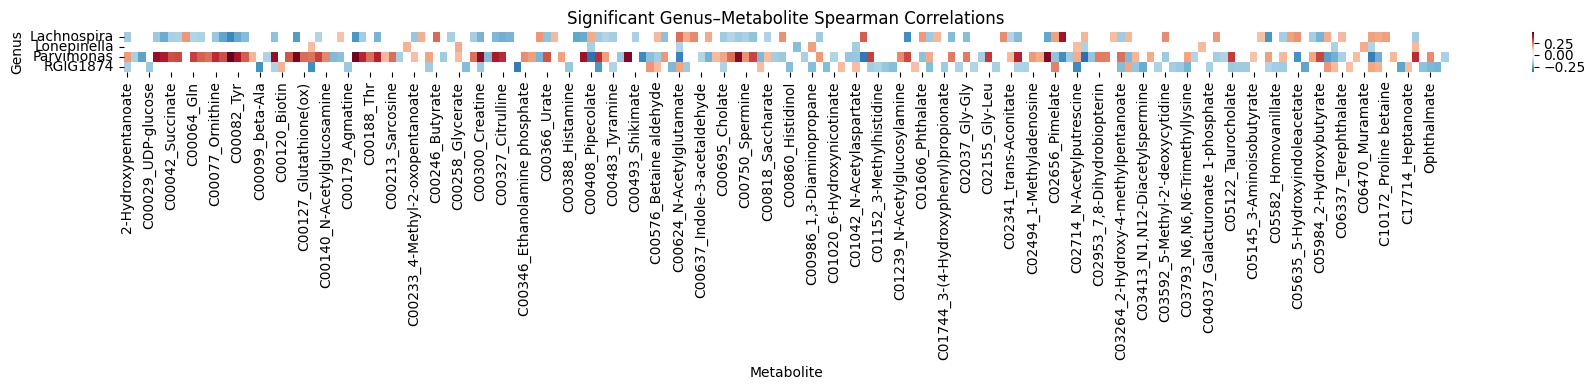

In [48]:
heatmap = significant_corr.pivot(
    index="Genus",
    columns="Metabolite",
    values="Spearman_rho"
)

plt.figure(figsize=(18,4))

sns.heatmap(
    heatmap,
    cmap="RdBu_r",
    center=0
)

plt.title("Significant Genus–Metabolite Spearman Correlations")

plt.tight_layout()

plt.show()

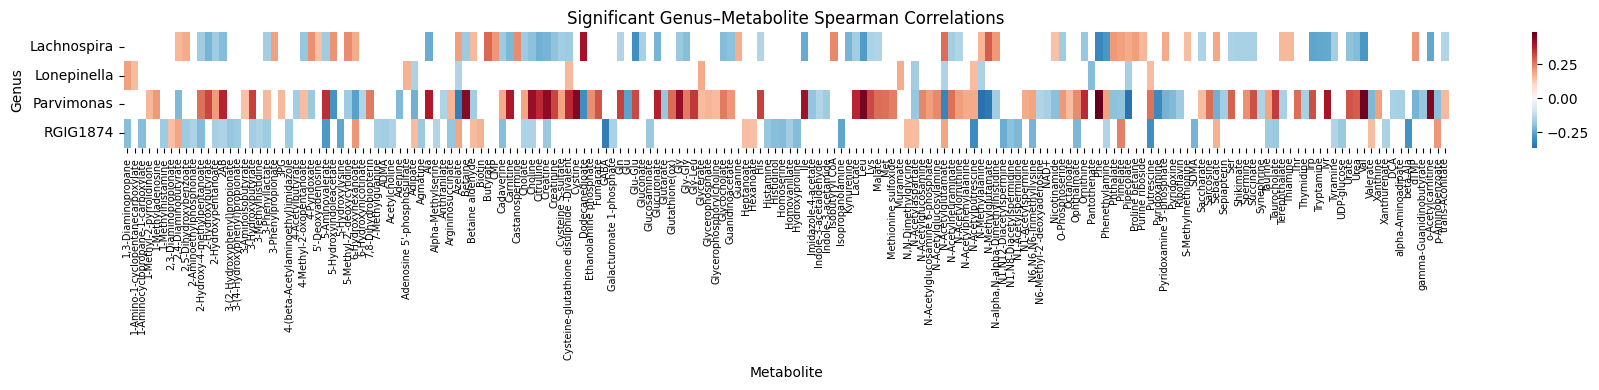

In [52]:
# Remove KEGG IDs (e.g. C00079_)
significant_corr["Metabolite_clean"] = (
    significant_corr["Metabolite"]
    .str.replace(r"^C\d+_", "", regex=True)
)

significant_corr.head()

heatmap = significant_corr.pivot(
    index="Genus",
    columns="Metabolite_clean",
    values="Spearman_rho"
)

plt.figure(figsize=(18,4))

sns.heatmap(
    heatmap,
    cmap="RdBu_r",
    center=0,
    xticklabels=True
)

plt.xticks(rotation=90, fontsize=7)
plt.title("Significant Genus–Metabolite Spearman Correlations")
plt.xlabel("Metabolite")
plt.ylabel("Genus")

plt.tight_layout()
plt.show()

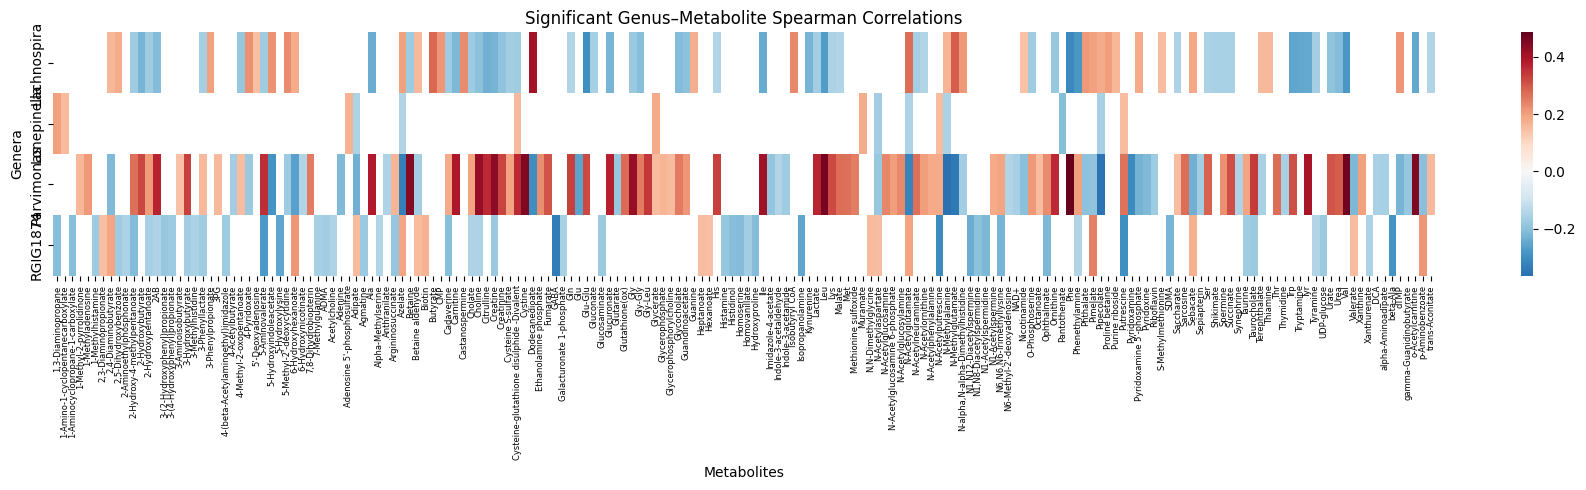

In [53]:
plt.figure(figsize=(18,5))

sns.heatmap(
    heatmap,
    cmap="RdBu_r",
    center=0,
    xticklabels=True,
    yticklabels=True
)

plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=10)

plt.xlabel("Metabolites")
plt.ylabel("Genera")
plt.title("Significant Genus–Metabolite Spearman Correlations")

plt.tight_layout()
plt.show()

The most obvious pattern is:

Parvimonas has many strong positive correlations (red), indicating it is positively associated with a large number of metabolites.
RGIG1874 is predominantly negatively correlated (blue) with many metabolites.
Lachnospira shows a mixture of positive and negative associations, suggesting more selective metabolic relationships.
Lonepinella has relatively few significant associations, indicating a weaker metabolic footprint in this dataset.

In [56]:
# Make heatmap matrix from significant correlations
heatmap = significant_corr.pivot(
    index="Genus",
    columns="Metabolite_clean",
    values="Spearman_rho"
)

# Replace missing cells with 0 correlation for plotting
heatmap_filled = heatmap.fillna(0)

# Check for remaining non-finite values
print(np.isfinite(heatmap_filled.values).all())

True


The NaN values were not biological results; they appeared because the pivot table only included significant genus–metabolite pairs, leaving blank cells for non-significant pairs. For visualization, these missing cells were filled with zero, meaning “no displayed significant correlation” in the heatmap.

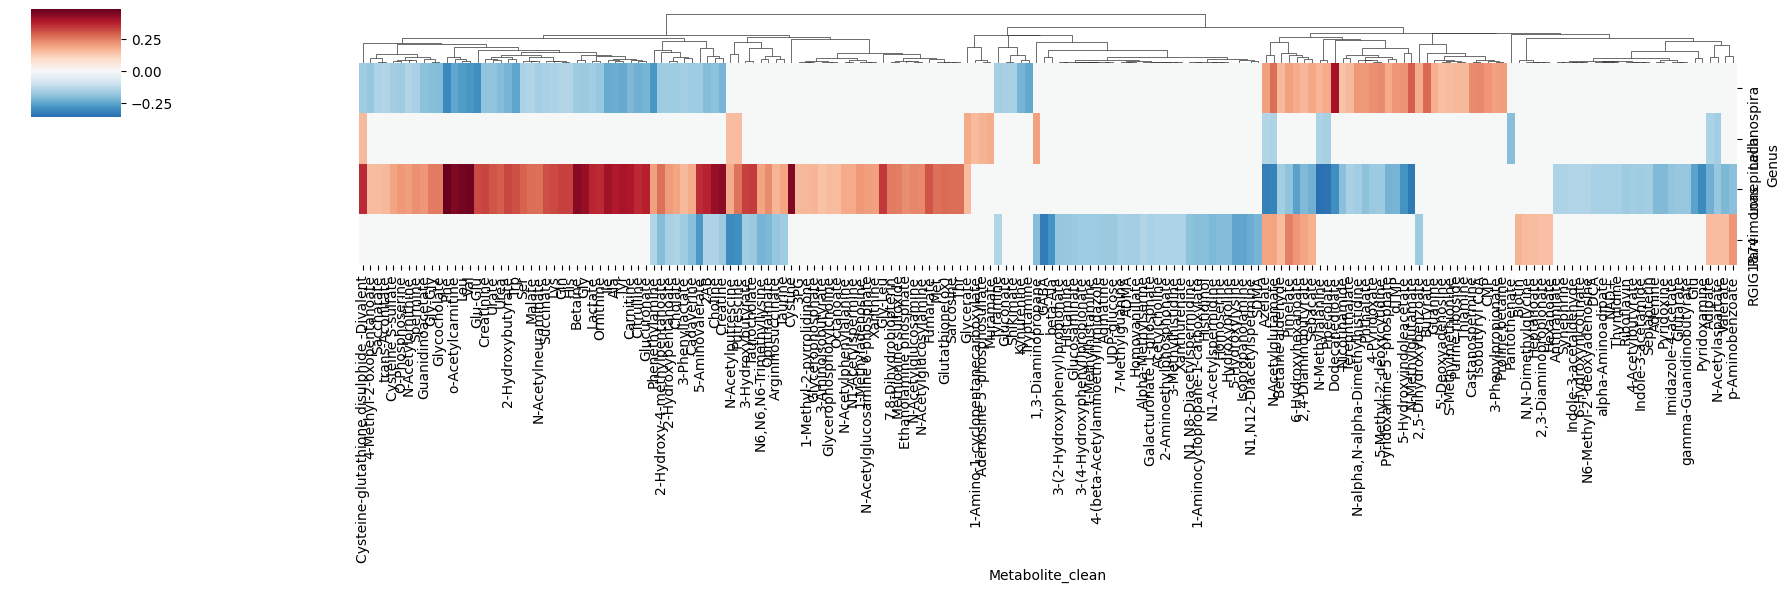

In [57]:
sns.clustermap(
    heatmap_filled,
    cmap="RdBu_r",
    center=0,
    figsize=(18, 6),
    col_cluster=True,
    row_cluster=False,
    xticklabels=True,
    yticklabels=True
)

plt.show()

The clustering reveals distinct metabolic signatures for each genus:

Parvimonas displays a large block of positive correlations (red), indicating that increased abundance of this genus is associated with increased levels of many metabolites.
RGIG1874 shows predominantly negative correlations (blue) for many of the same metabolites, suggesting an opposite metabolic association.
Lachnospira exhibits mixed positive and negative correlations, indicating more selective metabolic relationships.
Lonepinella has comparatively fewer significant associations, implying a weaker influence on the measured metabolome.

These opposing correlation patterns suggest that different bacterial genera are linked to distinct metabolic states in colorectal neoplasia.

Hierarchical clustering of significant genus–metabolite correlations revealed distinct metabolic association patterns for the four differentially abundant genera. Parvimonas showed widespread positive correlations with multiple metabolites, whereas RGIG1874 displayed predominantly negative correlations. Lachnospira exhibited a mixed pattern of positive and negative associations, while Lonepinella was associated with comparatively fewer metabolites. These findings indicate that colorectal cancer–associated microbial taxa are linked to distinct metabolic profiles, supporting coordinated alterations between the gut microbiome and metabolome.

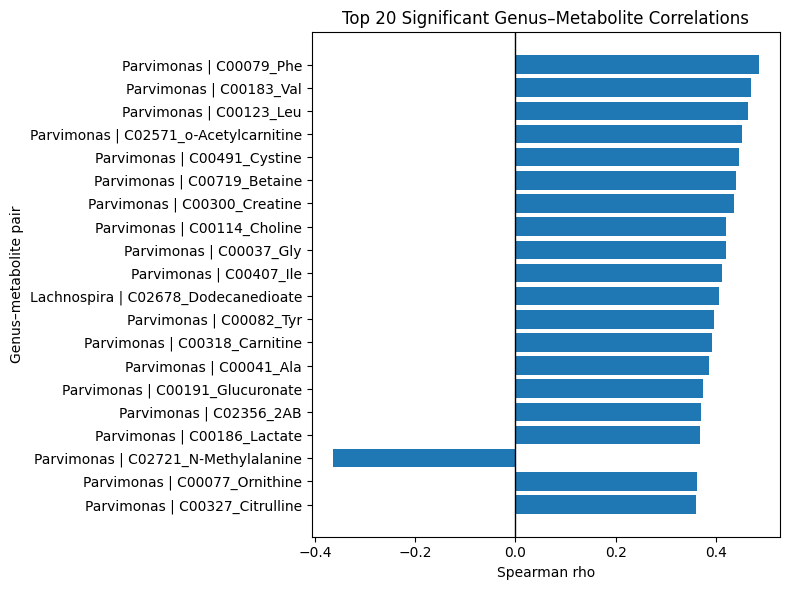

In [51]:
top_corr = significant_corr.copy()
top_corr["abs_rho"] = top_corr["Spearman_rho"].abs()
top_corr = top_corr.sort_values("abs_rho", ascending=False).head(20)

plt.figure(figsize=(8, 6))

plt.barh(
    top_corr["Genus"] + " | " + top_corr["Metabolite"],
    top_corr["Spearman_rho"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Spearman rho")
plt.ylabel("Genus–metabolite pair")
plt.title("Top 20 Significant Genus–Metabolite Correlations")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

<BarContainer object of 20 artists>

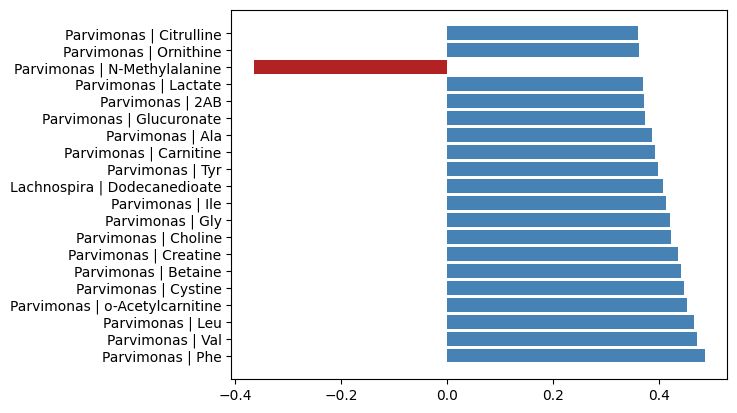

In [64]:
colors = [
    "steelblue" if x > 0 else "firebrick"
    for x in top_corr["Spearman_rho"]
]

plt.barh(
    top_corr["Genus"] + " | " + top_corr["Metabolite_clean"],
    top_corr["Spearman_rho"],
    color=colors
)

19 of the 20 strongest correlations are positive.
Parvimonas dominates the strongest microbiome–metabolome associations.
The correlated metabolites are enriched for amino acid and energy metabolism compounds (e.g., phenylalanine, valine, leucine, creatine, choline).
Only one of the top 20 associations is negative, indicating that the dominant trend is increasing metabolite abundance with increasing Parvimonas abundance.

Top 20 significant genus–metabolite correlations. Bars represent the strongest Spearman correlations between differentially abundant genera and metabolites after Benjamini–Hochberg FDR correction. Positive values indicate that higher microbial abundance is associated with higher metabolite levels, whereas negative values indicate inverse associations. The strongest correlations were predominantly observed for Parvimonas, particularly with amino acid–related metabolites such as phenylalanine, valine, and leucine.

In [62]:
top10_corr = (
    significant_corr
    .sort_values("FDR")
    .head(10)
    .copy()
)

# Round for presentation
top10_corr["Spearman_rho"] = top10_corr["Spearman_rho"].round(3)
top10_corr["p_value"] = top10_corr["p_value"].apply(lambda x: f"{x:.2e}")
top10_corr["FDR"] = top10_corr["FDR"].apply(lambda x: f"{x:.2e}")

top10_corr




,Genus,Metabolite,Metabolite,Spearman ρ,P-value,Adjusted P (FDR)
0,Parvimonas,C00079_Phe,Phe,0.485,6.53e-22,1.17e-18
1,Parvimonas,C00183_Val,Val,0.470,1.90e-20,1.69e-17
2,Parvimonas,C00123_Leu,Leu,0.465,5.64e-20,3.36e-17
3,Parvimonas,C02571_o-Acetylcarnitine,o-Acetylcarnitine,0.451,8.38e-19,3.74e-16
4,Parvimonas,C00491_Cystine,Cystine,0.447,2.04e-18,7.27e-16
5,Parvimonas,C00719_Betaine,Betaine,0.441,6.32e-18,1.88e-15
6,Parvimonas,C00300_Creatine,Creatine,0.435,1.81e-17,4.62e-15
7,Parvimonas,C00114_Choline,Choline,0.421,2.40e-16,5.35e-14
8,Parvimonas,C00037_Gly,Gly,0.420,2.76e-16,5.46e-14
9,Parvimonas,C00407_Ile,Ile,0.412,1.24e-15,2.21e-13


The strongest microbiome–metabolome associations were predominantly observed for Parvimonas, which showed moderate positive correlations with several amino acid metabolites, including phenylalanine, valine, leucine, glycine, and isoleucine. These findings suggest that the abundance of Parvimonas is closely associated with metabolic alterations linked to colorectal neoplasia.